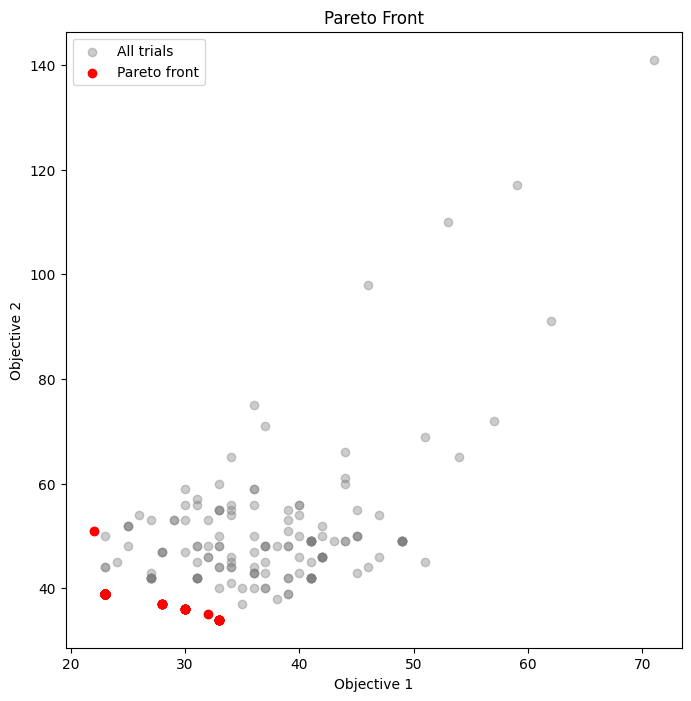

In [7]:
import optuna
import matplotlib.pyplot as plt

study = optuna.load_study(
    study_name="multi-objective-attraction",
    storage="sqlite:///optuna_study.db",
)

completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]

obj1 = [t.values[0] for t in completed]
obj2 = [t.values[1] for t in completed]

pareto_trials = study.best_trials
pareto_obj1 = [t.values[0] for t in pareto_trials]
pareto_obj2 = [t.values[1] for t in pareto_trials]

fig, ax = plt.subplots(figsize=(8, 8))  # equal width/height figure

ax.scatter(obj1, obj2, alpha=0.4, label="All trials", color="gray")
ax.scatter(pareto_obj1, pareto_obj2, color="red", label="Pareto front")

ax.set_xlabel("Objective 1")
ax.set_ylabel("Objective 2")
ax.set_title("Pareto Front")
ax.legend()

ax.set_box_aspect(1)  # forces the actual plotted box to be square regardless of data range

plt.savefig("pareto_front_manual.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
from optuna.visualization import plot_pareto_front

fig = plot_pareto_front(study, target_names=["objective_1", "objective_2"])

fig.update_layout(
    width=700,
    height=700,
    yaxis=dict(
        scaleanchor="x",   # locks y-axis scale to x-axis scale
        scaleratio=1,      # 1:1 ratio
    ),
)

fig.show()
fig.write_image("pareto_front.png")

/tmp/ipykernel_1531272/717299201.py:3: ExperimentalWarning:

plot_pareto_front is experimental (supported from v2.4.0). The interface can change in the future.



RuntimeError: 

Kaleido requires Google Chrome to be installed.

Either download and install Chrome yourself following Google's instructions for your operating system,
or install it from your terminal by running:

    $ plotly_get_chrome

